In [1]:
import shap
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cols = ['label',
        'lepton_pT', 'lepton_eta', 'lepton_phi',
        'missing_energy_magnitude', 'missing_energy_phi',
        'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
        'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
        'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
        'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag',
        'mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']

df = pd.read_csv('../data/HIGGS.csv', header=None, names=cols, nrows=500000)

X = df.drop('label', axis=1)
y = df['label']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Ready ✅")

Ready ✅


In [2]:
import joblib

xgb_model = joblib.load('../models/xgboost.pkl')

# use a sample of 5000 rows — full test set is too slow
X_sample = X_test.sample(5000, random_state=42)

explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_sample)

print("SHAP values computed ✅")

SHAP values computed ✅


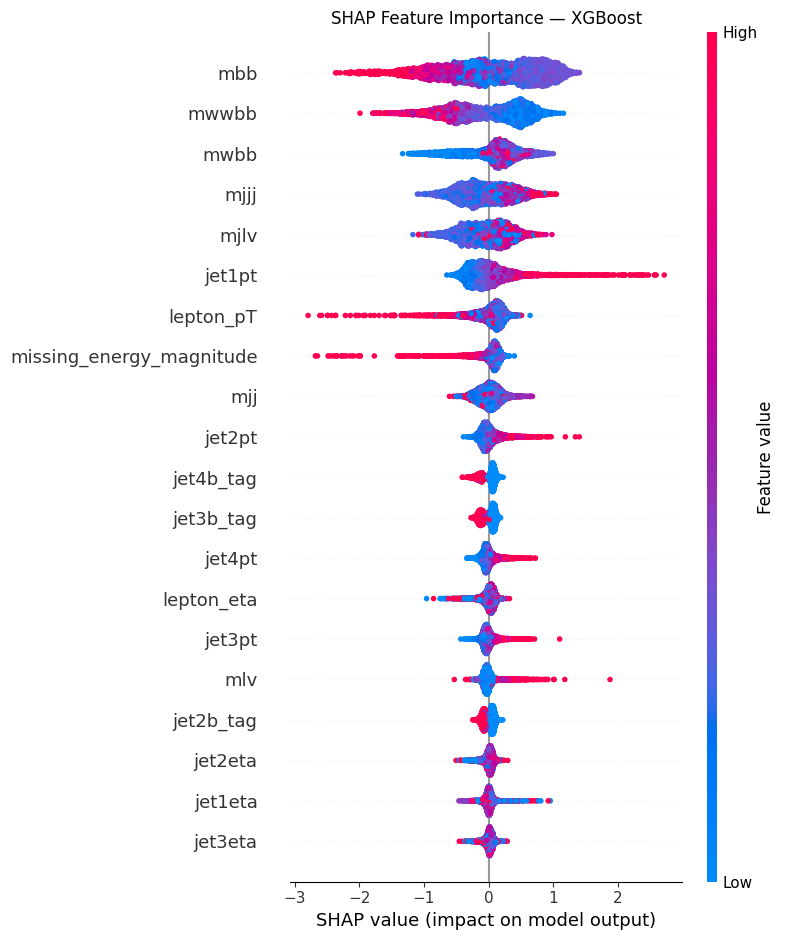

In [3]:
plt.figure()
shap.summary_plot(shap_values, X_sample, show=False)
plt.title('SHAP Feature Importance — XGBoost')
plt.tight_layout()
plt.savefig('../plots/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

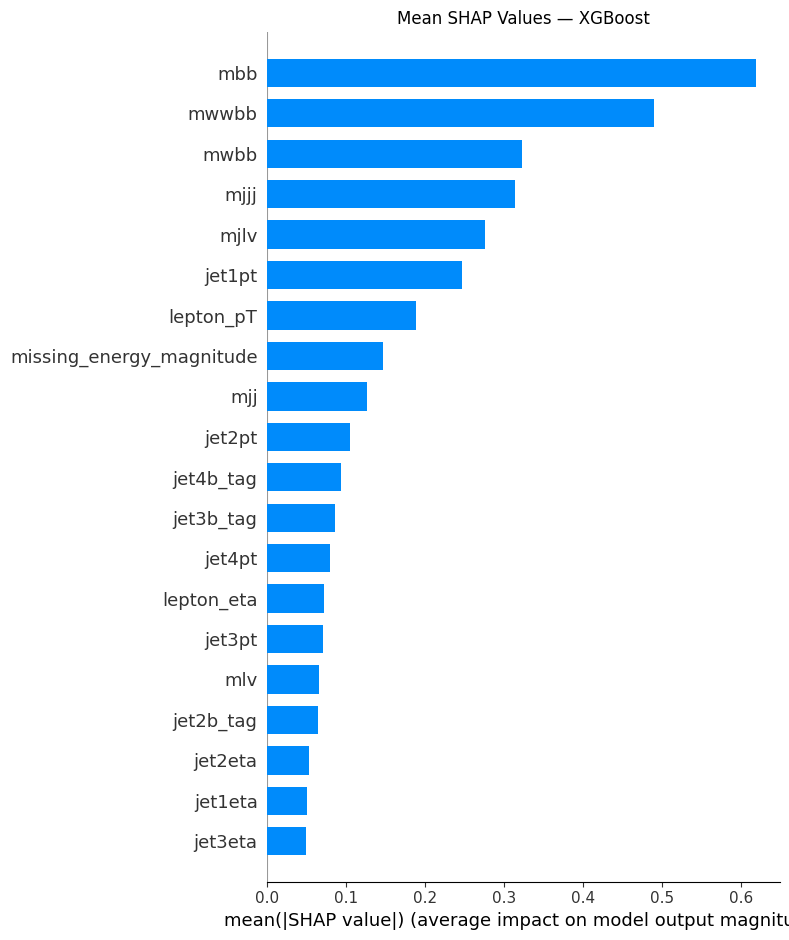

In [4]:
plt.figure()
shap.summary_plot(shap_values, X_sample, plot_type='bar', show=False)
plt.title('Mean SHAP Values — XGBoost')
plt.tight_layout()
plt.savefig('../plots/shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

## SHAP Analysis — Observations

### Feature Importance Ranking
The SHAP analysis reveals a clear hierarchy of feature importance
in the XGBoost model:

**High-level features dominate:** The top 5 most important features
are all physicist-engineered high-level quantities — mbb, mwwbb, mwbb,
mjjj, and mjlv. This confirms that invariant mass combinations carry
the most discriminating information for Higgs boson detection.
mbb alone has more than double the mean SHAP value of any low-level feature.

**mbb is the most important single feature** with a mean SHAP value
of ~0.62, significantly ahead of mwwbb (~0.49). Both represent
invariant masses of b-tagged jet combinations — physically meaningful
because Higgs boson decay produces characteristic b-quark signatures.

**Low-level features contribute but less:** jet1pt and lepton_pT are
the strongest raw detector measurements, ranking 6th and 7th. However
their combined importance is still less than mbb alone.

**Angular features are least informative:** jet eta and phi measurements
(jet1eta, jet2eta, jet3eta) appear at the bottom of the ranking with
minimal SHAP values. The angular position of jets carries little
discriminating power compared to their energy and mass combinations.

### Direction of Impact (Summary Plot)
- Low values of mbb and mwwbb strongly push predictions toward
  background (negative SHAP values, blue dots extending left)
- High values of jet1pt push toward signal (red dots extending right)
- Low lepton_pT and missing_energy_magnitude are strong indicators
  of background events

### Key Takeaway
The model relies primarily on high-level invariant mass features
that physicists deliberately engineered to capture Higgs decay
signatures. This validates the physics intuition behind feature
engineering and suggests that models trained on low-level features
alone would need to implicitly learn these mass relationships —
a task better suited to deeper neural networks than gradient boosting.